![Banner](../images/09_10_banner_rs_object_detection.png)


# Field Edge Detection in WorldView Imagery: RGB versus RGB + NIR

In this notebook you will repeat a published field-boundary study on a WorldView scene of Patuakhali, Bangladesh. You will build a boundary reference from digitised fields, compare classical edge detectors, a texture random forest and six deep networks on red-green-blue and on red-green-blue-NIR input, and turn the best boundary map into field polygons with `geolattice.rsense.edge_detectors`.


## Overview

Smallholder fields in southern Bangladesh average about a tenth of a hectare and are separated by paddy bunds (dikes) that are often only 0.3 m wide, narrower than one multispectral pixel. Knowing where these fields are is the basis for crop statistics, yield estimates and targeted advice, but no cadastre records them.

This notebook repeats, step by step, the study

> Yang, R., Ahmed, Z. U., Schulthess, U. C., Kamal, M., & Rai, R. (2020). Detecting functional field units from satellite images in smallholder farming systems using a deep learning based computer vision approach: A case study from Bangladesh. *Remote Sensing Applications: Society and Environment*, 20, 100413. https://doi.org/10.1016/j.rsase.2020.100413

on the WorldView scene of Patuakhali District shipped with GeoLattice (`Data/08_remote_sensing/08_10_object_detection/Edge_Detection/BD_WorldView`), with the tools in `geolattice.rsense.edge_detectors`:

| Paper | This notebook | GeoLattice |
|---|---|---|
| 2.2 Field outlines digitised, buffered by 0.5 m, rasterised at 0.5 m: class 1 boundary, class 2 non-boundary | Boundary reference | `ed.rasterize_boundaries` |
| 2.3 Split into 192 x 192 tiles; 90°, 180°, 270° rotations | Tiles and split | `ed.tile_pairs`, `ed.dihedral_augment` |
| Edge detectors cited as the classical approach (Roberts, Sobel, LoG, Canny) | Traditional edge detectors | `ed.classical_edges` |
| 2.4.2 Random forest, 600 trees, depth 30, LBP and GLCM texture | Random forest | `texture.lbp_texture`, `texture.glcm_texture` |
| 2.4.1 U-Net, SegNet, FC-DenseNet56/67/103, FCN-DKConv6 | The six networks | `ed.build_edge_model` |
| Table 6 hyper-parameter sensitivity | Learning-rate sensitivity | `ic.train_model` |
| 2.5 Precision, recall, F1 (Eqs. 1-3), ROC and AUC; Tables 7-8, Figs. 8-11 | Evaluation protocol, Results | `ed.edge_metrics`, `ed.select_threshold` |
| 3 channels (blue, green, red) vs 4 channels (+ NIR2) | every step | `BANDS` |
| (beyond the paper) fields as polygons | Field polygons | `ed.detect_field_edges` |


## Core concepts

### Learning objectives

1. Build a 0.5 m boundary reference from digitised fields, and split tiles so rotated copies do not leak into the test set.
2. Compare traditional edge detectors, a texture random forest and the six networks from Yang et al. (2020) on the same tiles.
3. Score boundary maps with precision, recall, F1, ROC and AUC, and see how a positional tolerance changes F1.
4. Compare red-green-blue input with red-green-blue plus NIR2 at every step.
5. Turn the best boundary probability into georeferenced field polygons and compare them with the digitised fields.
6. Place this replication next to the published test scores and state what does and does not reproduce.

### Contents

1. What differs from the paper
2. Setup
3. Data
4. The boundary reference on a 0.5 m grid
5. Tiles, a spatial split, normalisation and rotation augmentation
6. Evaluation protocol
7. Traditional edge detectors
8. Random forest on texture features
9. The six networks
10. Results
11. From boundary probability to field polygons
12. Comparison with the published results
13. Discussion


## What differs from the paper

- **Image.** The shipped scene is an eight-band subset at **1.6 m**; the paper reports a 1.24 m WorldView-3 acquisition (18 March 2015). Both are resampled to the 0.5 m label grid.
- **Split before augmenting.** The paper rotated its 51 tiles into 204 and then split them 172 / 8 / 24, so rotated copies of one tile can sit in training and test. Here whole blocks of 2 x 2 tiles are assigned to train, validation or test first, and only training tiles are rotated. This removes that leak, so the test scores here are expected to be lower.
- **Training budget.** The paper trained for 500 epochs, batch size 1, learning rate 1e-4 (TensorFlow 1.14). Here: PyTorch, 60 (SegNet 150) epochs, batch size 4, learning rate 1e-3 (chosen in *Learning-rate sensitivity*), cosine schedule, best epoch by validation mean IoU.
- **SegNet settings.** With dropout after all ten stages, or with the plain loss, SegNet predicted "non-boundary" everywhere on these 180 training tiles. It uses dropout only at the three deepest encoder and decoder stages (the Bayesian SegNet placement), class-weighted cross-entropy and 150 epochs.
- **Scored area.** Villages, ponds and roads were not digitised. Loss and scores use only pixels inside a digitised field or its boundary band.


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [ ]:
# Setup: libraries, GeoLattice modules, device, paths and the random seed.
import time, warnings                                # timing and warning control
from pathlib import Path                             # portable file paths

import numpy as np                                   # arrays
import pandas as pd                                  # result tables
import geopandas as gpd                              # the digitised field polygons
import matplotlib.pyplot as plt                      # figures
import rasterio                                      # read and write GeoTIFFs
from rasterio.enums import Resampling                # resampling methods
from rasterio.transform import from_origin           # build the 0.5 m grid transform
import torch                                         # PyTorch: networks and the GPU

import geolattice.rsense as rs                            # GeoLattice remote sensing (for the version)
from geolattice.rsense import edge_detectors as ed        # field-boundary tools: labels, tiles, models, metrics
from geolattice.rsense import texture                     # LBP and GLCM texture for the random forest
import geolattice.rsense.classify.image_classification as ic   # training loop, seeds and split checks

warnings.filterwarnings("ignore")                    # hide library warnings
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10})
SEED = 2020
ic.set_seed(SEED)                                    # same random numbers in NumPy, Python and PyTorch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"   # use the GPU when available

DATA = Path("../../../../Data/08_remote_sensing/08_10_object_detection/Edge_Detection/BD_WorldView")      # WorldView scene and digitised fields
if not DATA.is_dir():
    raise FileNotFoundError("Run this notebook from the 09_09_image_classification folder")
OUT = Path("outputs/field_edge_worldview")           # trained models, probability raster and polygons
OUT.mkdir(parents=True, exist_ok=True)
print(f"geolattice.rsense {rs.__version__} | torch {torch.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print("edge models in GeoLattice:", ed.available_models())     # names accepted by ed.build_edge_model

geolattice.rsense 0.3.35 | torch 2.14.0+cu132 | device cuda (NVIDIA RTX A5500 Laptop GPU)
edge models in GeoLattice: ['FC-DenseNet56', 'FC-DenseNet67', 'FC-DenseNet103', 'SegNet', 'FCN-DKConv6', 'unet', 'unet_basic', 'unetplusplus', 'deeplabv3plus', 'deeplabv3', 'fcn_resnet50', 'fcn_resnet101', 'deeplabv3_resnet50', 'deeplabv3_resnet101', 'deeplabv3_mobilenet', 'lraspp_mobilenet', 'fpn', 'manet', 'pspnet', 'segformer', 'upernet']


## Data

`multi.tif` holds eight WorldView bands in the order coastal, blue, green, yellow, red, red edge, NIR1, NIR2 (B1-B8). The paper used **blue, green, red and NIR2**: B2, B3, B5 and B8. `aoi_trianing.shp` (spelling as shipped) contains the digitised parcels with a `Class` attribute (Crop or Fallow).


In [ ]:
# Read the WorldView scene and audit its eight bands.
with rasterio.open(DATA / "multi.tif") as src:
    X8 = src.read().astype("float32")                       # all eight bands: (8, rows, columns)
    TRANSFORM, CRS, NODATA = src.transform, src.crs, src.nodata
    BOUNDS, RES = src.bounds, src.res[0]                    # extent and pixel size (m)
BAND_NAMES = ["B1 coastal", "B2 blue", "B3 green", "B4 yellow", "B5 red", "B6 red edge", "B7 NIR1", "B8 NIR2"]
X8[X8 <= -1e30] = np.nan                                   # the file's nodata value (-3.4e38)
fill = X8 == 65535                                         # saturated fill values
# Per band: share of no-data and fill pixels, and the 2nd percentile, median and 98th percentile.
audit = pd.DataFrame({"band": BAND_NAMES,
                      "nodata %": [100 * np.isnan(b).mean() for b in X8],
                      "65535 fill %": [100 * f.mean() for f in fill],
                      "p2": [np.nanpercentile(b[~f], 2) for b, f in zip(X8, fill)],
                      "median": [np.nanmedian(b[~f]) for b, f in zip(X8, fill)],
                      "p98": [np.nanpercentile(b[~f], 98) for b, f in zip(X8, fill)]}).set_index("band")
H0, W0 = X8.shape[1:]                                      # native rows and columns
print(f"{W0} x {H0} pixels of {RES:g} m ({(BOUNDS.right - BOUNDS.left):.0f} m x {(BOUNDS.top - BOUNDS.bottom):.0f} m), {CRS}")
display(audit.round(1))

# The paper compared blue-green-red (3 channels) with blue-green-red-NIR2 (4 channels).
BANDS = {"3ch (B, G, R)": [1, 2, 4], "4ch (B, G, R, NIR2)": [1, 2, 4, 7]}   # 0-based: B2, B3, B5, B8
SCENE_OK = np.isfinite(X8[1:]).all(0) & ~fill[1:].any(0)   # pixels valid in every band except B1
print(f"pixels valid in bands 2-8: {SCENE_OK.mean():.1%} (band 1 is not used)")

# Field polygons: 'Class' is Crop or Fallow. The shapefile has no .prj; its coordinates are
# in the raster's UTM 46N metres (checked by the bounds below), so that CRS is assigned.
fields = gpd.read_file(DATA / "aoi_trianing.shp")
print("shapefile CRS:", fields.crs, "| bounds:", fields.total_bounds.round(0), "| raster:", tuple(round(v) for v in BOUNDS))
fields = fields.set_crs(CRS, allow_override=True)
fields["area_ha"] = fields.area / 1e4                       # field area in hectares
print(f"{len(fields)} digitised fields ({fields.Class.value_counts().to_dict()}); "
      f"mean area {fields.area_ha.mean():.3f} ha, median {fields.area_ha.median():.3f} ha "
      f"(paper: 557 fields, mean 0.105 ha)")

760 x 702 pixels of 1.6 m (1216 m x 1123 m), EPSG:32646


,nodata %,65535 fill %,p2,median,p98
band,,,,,
B1 coastal,1.1,38.3,3.0,95.0,562.000000
B2 blue,1.1,0.0,142.0,678.0,994.000000
B3 green,1.1,0.0,338.0,1097.0,1491.000000
B4 yellow,1.1,0.0,307.0,1209.0,1741.000000
B5 red,1.1,0.0,233.0,1218.0,1854.000000
B6 red edge,1.1,0.0,838.0,2062.0,2575.600098
B7 NIR1,1.1,0.0,935.0,2645.0,3844.000000
B8 NIR2,1.1,0.0,832.0,2699.0,3924.000000


pixels valid in bands 2-8: 98.9% (band 1 is not used)
shapefile CRS: None | bounds: [ 225411. 2464938.  226623. 2466029.] | raster: (225408, 2464906, 226624, 2466029)


567 digitised fields ({'Crop': 480, 'Fallow': 87}); mean area 0.122 ha, median 0.070 ha (paper: 557 fields, mean 0.105 ha)


The coastal band (B1) is filled with 65535 over about 38 % of the scene, which is one more reason to leave it out; the four bands used here are clean. The shapefile has no projection file, but its coordinates fall inside the raster's UTM 46N extent, so it is given that CRS.

## The boundary reference on a 0.5 m grid

Following section 2.2 of the paper, every field outline is buffered by 0.5 m (a 1 m wide band), burnt into a 0.5 m raster as the **boundary** class, and the rest of each field is the **non-boundary** (field) class. The image is resampled to the same 0.5 m grid with bilinear interpolation. This does not add detail; it only puts image and labels on one grid.


0.5 m grid: 2432 x 2246 pixels | labelled area 51% of the scene | boundary pixels 10.5% of the labelled area


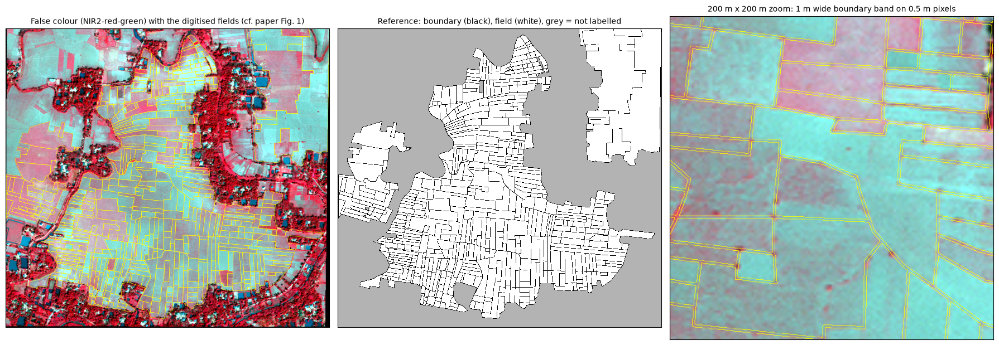

In [ ]:
# A 0.5 m working grid and the two-class boundary reference.
from rasterio.warp import reproject                        # resample a raster onto another grid

# The paper rasterised the boundaries at 0.5 m, so the image is resampled to the same grid
# (bilinear; resampling adds no detail, it only puts image and labels on one grid).
GSD = 0.5
T05 = from_origin(BOUNDS.left, BOUNDS.top, GSD, GSD)       # transform of the 0.5 m grid (same top-left corner)
H, W = int(round((BOUNDS.top - BOUNDS.bottom) / GSD)), int(round((BOUNDS.right - BOUNDS.left) / GSD))
X05 = np.full((8, H, W), np.nan, "float32")                # empty 0.5 m image, filled band by band
src_img = np.where(fill, np.nan, X8)                       # treat fill values as no-data
for b in range(8):
    reproject(src_img[b], X05[b], src_transform=TRANSFORM, src_crs=CRS, dst_transform=T05, dst_crs=CRS,
              resampling=Resampling.bilinear, src_nodata=np.nan, dst_nodata=np.nan)
ok05 = np.isfinite(X05[1:]).all(0)                         # valid 0.5 m pixels in bands 2-8

# Paper, section 2.2: each field outline is buffered by 0.5 m -> class 1 (boundary);
# the rest of the field -> class 0 here (the paper's "class 2", non-boundary).
# `labelled` marks pixels inside a digitised field or its boundary band; villages, ponds and
# roads that nobody digitised are left out of training and scoring.
BOUNDARY, labelled = ed.rasterize_boundaries(fields, transform=T05, shape=(H, W), buffer=0.5, return_valid=True)
VALID = labelled & ok05                                    # pixels that are labelled and have image data
print(f"0.5 m grid: {W} x {H} pixels | labelled area {VALID.mean():.0%} of the scene | "
      f"boundary pixels {BOUNDARY[VALID].mean():.1%} of the labelled area")

def false_colour(x, bands=(7, 4, 2), lo=None, hi=None):
    """NIR2-red-green false colour (vegetation red), 2-98 % stretch per band."""
    rgb = np.stack([x[b] for b in bands], -1)                          # (H, W, 3)
    lo = np.nanpercentile(rgb, 2, axis=(0, 1)) if lo is None else lo   # per-band 2nd percentile
    hi = np.nanpercentile(rgb, 98, axis=(0, 1)) if hi is None else hi  # per-band 98th percentile
    return np.nan_to_num(np.clip((rgb - lo) / (hi - lo), 0, 1))

FC = false_colour(X05)
EXT = (BOUNDS.left, BOUNDS.right, BOUNDS.bottom, BOUNDS.top)          # plot extent in map units
fig, ax = plt.subplots(1, 3, figsize=(18, 6.2))
ax[0].imshow(FC, extent=EXT); fields.boundary.plot(ax=ax[0], color="yellow", lw=0.4)
ax[0].set_title("False colour (NIR2-red-green) with the digitised fields (cf. paper Fig. 1)")
lab_img = np.where(VALID, BOUNDARY, np.nan)                            # NaN = not labelled (drawn grey)
ax[1].imshow(lab_img, cmap="gray_r", extent=EXT, interpolation="nearest")
ax[1].set_title("Reference: boundary (black), field (white), grey = not labelled")
ax[1].set_facecolor("0.7")
zoom = (slice(900, 1300), slice(1000, 1400))                           # 400 x 400 pixels = 200 m x 200 m
ax[2].imshow(FC[zoom]); ax[2].contour(BOUNDARY[zoom], levels=[0.5], colors="yellow", linewidths=0.6)
ax[2].set_title("200 m x 200 m zoom: 1 m wide boundary band on 0.5 m pixels")
for a in ax:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

Boundaries are only about 10.5 % of the labelled pixels, so a classifier that never predicts a boundary would already be about 89.5 % "accurate". This is why the paper reports precision, recall and F1 of the **boundary** class, not overall accuracy.

## Tiles, a spatial split, normalisation and rotation augmentation

- **Tiles.** 192 x 192 pixels (96 m x 96 m), the paper's best image size (Table 6). Tiles less than half digitised are dropped.
- **Split.** Neighbouring tiles share fields and bunds, so whole 2 x 2-tile blocks go to one split (about 70 / 10 / 20 % of tiles for train / validation / test). `ic.check_split_isolation` raises an error if a tile ends up in two splits.
- **Normalisation.** Each band is stretched to [0, 1] between its 2nd and 98th percentiles, computed on training tiles only.
- **Augmentation.** Training tiles are rotated by 90°, 180° and 270° (`ed.dihedral_augment`), four copies of each tile, as in the paper's Fig. 3. Validation and test tiles are not augmented.


71 tiles of 192 x 192 pixels (paper: 51)
{'train': 45, 'val': 11, 'test': 15} tiles


training set after rotation: 180 tiles; validation 11, test 15


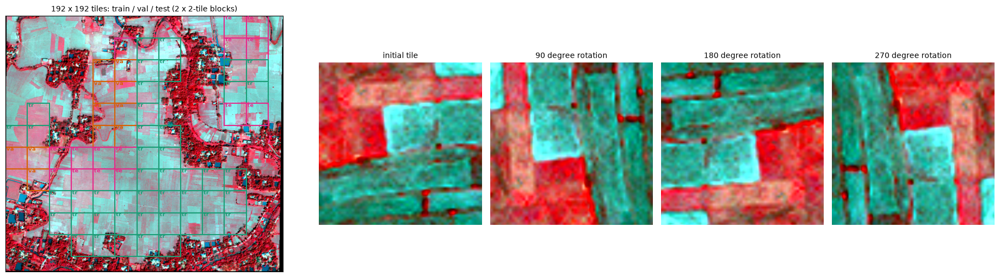

In [ ]:
# Tiles, a spatial split, normalisation and rotation augmentation.

# 192 x 192 tiles (96 m x 96 m) as in the paper; keep tiles at least half labelled.
TILE = 192
LABEL = np.where(VALID, BOUNDARY, 0).astype("int64")                   # 0/1 label, 0 where unlabelled
tiles = ed.tile_pairs(np.moveaxis(X05, 0, -1), LABEL, size=TILE, valid=VALID, min_valid=0.5)
n_tiles = len(tiles["labels"])                                         # tiles: images, labels, valid, origins
print(f"{n_tiles} tiles of {TILE} x {TILE} pixels (paper: 51)")

# Spatial split. Neighbouring tiles share fields, so whole 2 x 2-tile blocks (192 m) go to one
# side. The paper split *after* augmenting (172/8/24 of 204 tiles), which can put rotated
# copies of one tile on both sides; here the split comes first and only training tiles are rotated.
rng = np.random.default_rng(SEED)
block = [tuple(o // (2 * TILE)) for o in tiles["origins"]]             # block (row, col) of each tile
blocks = sorted(set(block))
rng.shuffle(blocks)                                                    # random block order
split_of_block, counts = {}, {"test": 0, "val": 0, "train": 0}
for b in blocks:
    n = block.count(b)                                                 # tiles in this block
    # Fill the test split to 20 % of the tiles first, then validation to 10 %, the rest is training.
    side = "test" if counts["test"] < 0.2 * n_tiles else "val" if counts["val"] < 0.1 * n_tiles else "train"
    split_of_block[b] = side
    counts[side] += n
SPLIT = np.array([split_of_block[b] for b in block])                   # split of every tile
idx = {s: np.flatnonzero(SPLIT == s) for s in ("train", "val", "test")}   # tile indices per split
tile_id = np.array([f"r{r}_c{c}" for r, c in tiles["origins"]])
ic.check_split_isolation(**{s: tile_id[v] for s, v in idx.items()})          # raises if a tile is in two splits
print({s: len(v) for s, v in idx.items()}, "tiles")

# Normalise each band to [0, 1] with its 2nd and 98th percentiles over the training tiles only.
tr_px = tiles["images"][idx["train"]].transpose(1, 0, 2, 3).reshape(8, -1)   # (8 bands, all training pixels)
LO = np.nanpercentile(tr_px, 2, axis=1)[:, None, None]
HI = np.nanpercentile(tr_px, 98, axis=1)[:, None, None]
def normalise(x):
    """(..., 8, H, W) raw reflectance -> [0, 1], NaN -> 0."""
    return np.nan_to_num(np.clip((x - LO) / (HI - LO), 0, 1)).astype("float32")
X_all = normalise(tiles["images"])                       # (N, 8, 192, 192)
Y_all = np.where(tiles["valid"], tiles["labels"], -100)  # -100 = not labelled (ignored in the loss)

# Augment the training tiles with 90, 180 and 270 degree rotations (paper Fig. 3).
Xtr, Ytr = ed.dihedral_augment(X_all[idx["train"]], Y_all[idx["train"]], rotations=(0, 1, 2, 3))
print(f"training set after rotation: {len(Xtr)} tiles; validation {len(idx['val'])}, test {len(idx['test'])}")

# Where the splits are, and one training tile with its four rotations.
fig = plt.figure(figsize=(19, 5.2))
a0 = fig.add_subplot(1, 6, (1, 2))                                    # the map spans two panel widths
a0.imshow(FC); a0.set_xticks([]); a0.set_yticks([])
colours = {"train": "#1b9e77", "val": "#d95f02", "test": "#e7298a"}
for (r, c), s_ in zip(tiles["origins"], SPLIT):
    a0.add_patch(plt.Rectangle((c, r), TILE, TILE, fill=False, ec=colours[s_], lw=1.5))   # tile outline
    a0.text(c + 8, r + 30, s_[:2], color=colours[s_], fontsize=7, weight="bold")         # "tr", "va" or "te"
a0.set_title("192 x 192 tiles: train / val / test (2 x 2-tile blocks)")
i0 = idx["train"][np.argmax(tiles["valid"][idx["train"]].mean((1, 2)))]   # the best-labelled training tile
for k in range(4):
    a = fig.add_subplot(1, 6, 3 + k)
    a.imshow(np.rot90(false_colour(tiles["images"][i0]), k, axes=(0, 1)))   # rotate by k x 90 degrees
    a.set_title(["initial tile", "90 degree rotation", "180 degree rotation", "270 degree rotation"][k]); a.axis("off")
plt.tight_layout(); plt.show()

## Evaluation protocol

For the boundary class, with TP, FP and FN counted over the scored pixels of the tiles (paper Eqs. 1-3):

$$\text{Precision} = \frac{TP}{TP + FP}, \qquad \text{Recall} = \frac{TP}{TP + FN}, \qquad F_1 = 2\,\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision} + \text{Recall}}$$

The same is computed for the non-boundary (field, the paper's "cropland") class. AUC, the area under the ROC curve, uses the continuous score and needs no threshold. Every method gives a score per pixel (a probability or an edge strength). It is turned into a boundary map with the threshold that maximises boundary F1 on the **validation** tiles (`ed.select_threshold`). The test tiles are scored once, with that threshold.


In [ ]:
# Evaluation protocol shared by every method.
SCENE = normalise(X05)                       # (8, H, W) in [0, 1], same normalisation as the tiles
ORIG = tiles["origins"]                      # top-left (row, col) of every tile
TRUTH = tiles["labels"]                      # (N, 192, 192) 0/1
SCORED = tiles["valid"]                      # pixels inside the digitised area

def cut(score2d, which):
    """Tiles of a full-scene score map for the tile indices `which`."""
    return np.stack([score2d[r:r + TILE, c:c + TILE] for r, c in ORIG[which]])

RESULTS, CURVES, SCORES = [], {}, {}         # metric rows, ROC curves and score tiles of every method

def evaluate(name, channels, tile_scores, *, kind, threshold=None, tolerance=0):
    """Pick the threshold on the validation tiles (maximum boundary F1), then score the
    train, val and test tiles. `tile_scores(split)` returns (n, 192, 192) boundary scores."""
    s_val = tile_scores("val")
    if threshold is None:                    # Canny passes a fixed threshold; all others are tuned
        threshold, _ = ed.select_threshold(s_val, TRUTH[idx["val"]], valid=SCORED[idx["val"]], tolerance=tolerance)
    for split in ("train", "val", "test"):
        s = s_val if split == "val" else tile_scores(split)
        SCORES[(name, channels, split)] = s
        # Boundary and field precision, recall, F1 and AUC of this split.
        m = ed.edge_metrics(s, TRUTH[idx[split]], threshold=threshold, valid=SCORED[idx[split]], tolerance=tolerance)
        RESULTS.append({"method": name, "kind": kind, "channels": channels, "split": split, "tolerance_px": tolerance, **m})
        if split == "test" and tolerance == 0:
            # ROC curve on the test tiles, from a random sample of at most 300,000 scored pixels.
            from sklearn.metrics import roc_curve
            ok = SCORED[idx["test"]]
            pick = np.random.default_rng(0).choice(ok.sum(), min(300_000, ok.sum()), replace=False)
            fpr, tpr, _ = roc_curve(TRUTH[idx["test"]][ok][pick], s[ok][pick])
            CURVES[(name, channels)] = (fpr, tpr, m["auc"])
    return threshold

def table(split="test", tolerance=0, cols=("boundary_precision", "boundary_recall", "boundary_f1",
                                            "field_precision", "field_recall", "field_f1", "auc")):
    # Results of one split and tolerance as a table indexed by kind, method and band set.
    df = pd.DataFrame(RESULTS)
    df = df[(df.split == split) & (df.tolerance_px == tolerance)]
    return df.set_index(["kind", "method", "channels"])[list(cols)].round(3)

print(f"scored pixels: train {SCORED[idx['train']].sum():,}, val {SCORED[idx['val']].sum():,}, test {SCORED[idx['test']].sum():,}; "
      f"boundary share on test {TRUTH[idx['test']][SCORED[idx['test']]].mean():.1%}")

scored pixels: train 1,519,536, val 357,429, test 509,188; boundary share on test 7.6%


## Traditional edge detectors

The paper's introduction names the classical detectors that preceded learning methods. Each one measures how fast brightness changes:

- **Roberts**: 2 x 2 diagonal differences.
- **Sobel** and **Prewitt**: 3 x 3 smoothed derivatives in x and y; the gradient magnitude is $\sqrt{G_x^2 + G_y^2}$.
- **Laplacian of Gaussian** (LoG): $|\nabla^2 (G_\sigma * I)|$, the second derivative after Gaussian smoothing.
- **Canny**: smoothing, gradient, non-maximum suppression and hysteresis thresholds. It returns thin binary edges, so it has a single operating point instead of a score.

`ed.classical_edges` runs the detector on every band and keeps the maximum response (a multispectral gradient), so adding NIR2 can only add edges that are visible in that band. None of these methods learns what a *field* boundary looks like: they respond equally to a bund, a tree crown or a pond shore.


10 edge maps scored in 14 s


,,boundary_precision,boundary_recall,boundary_f1,field_f1,auc
method,channels,,,,,
Roberts,"3ch (B, G, R)",0.267,0.385,0.315,0.930,0.718
Sobel,"3ch (B, G, R)",0.266,0.449,0.334,0.924,0.738
Prewitt,"3ch (B, G, R)",0.266,0.450,0.335,0.924,0.739
Laplacian of Gaussian,"3ch (B, G, R)",0.180,0.349,0.237,0.904,0.659
Canny,"3ch (B, G, R)",0.259,0.169,0.204,0.947,0.564
Roberts,"4ch (B, G, R, NIR2)",0.226,0.550,0.320,0.898,0.754
Sobel,"4ch (B, G, R, NIR2)",0.302,0.460,0.364,0.932,0.768
Prewitt,"4ch (B, G, R, NIR2)",0.301,0.461,0.364,0.932,0.768
Laplacian of Gaussian,"4ch (B, G, R, NIR2)",0.225,0.361,0.277,0.920,0.700


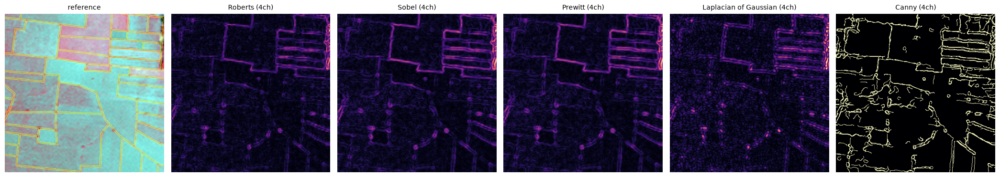

In [ ]:
# Traditional edge detectors on 3 and 4 channels.
# name -> (method name in ed.classical_edges, Gaussian smoothing sigma in pixels)
CLASSICAL = {"Roberts": ("roberts", 0.0), "Sobel": ("sobel", 1.0), "Prewitt": ("prewitt", 1.0),
             "Laplacian of Gaussian": ("log", 2.0), "Canny": ("canny", 2.0)}
edge_maps = {}
t0 = time.perf_counter()
for ch, bands in BANDS.items():
    img = np.moveaxis(SCENE[bands], 0, -1)                   # (H, W, bands) for ed.classical_edges
    for name, (method, sigma) in CLASSICAL.items():
        score = ed.classical_edges(img, method, sigma=sigma)  # edge strength of the whole scene in [0, 1]
        edge_maps[(name, ch)] = score
        # Score the tiles; Canny is binary, so it gets a fixed threshold of 0.5.
        evaluate(name, ch, lambda split, s=score: cut(s, idx[split]), kind="1 classical",
                 threshold=0.5 if method == "canny" else None)
print(f"{len(edge_maps)} edge maps scored in {time.perf_counter() - t0:.0f} s")
display(table().loc["1 classical"].drop(columns=["field_precision", "field_recall"]))

# The reference and the five 4-channel edge maps in a 200 m x 200 m window.
zoom = (slice(900, 1300), slice(1000, 1400))
fig, ax = plt.subplots(1, 6, figsize=(21, 3.9))
ax[0].imshow(FC[zoom]); ax[0].contour(BOUNDARY[zoom], levels=[0.5], colors="yellow", linewidths=0.5); ax[0].set_title("reference")
for a, name in zip(ax[1:], CLASSICAL):
    a.imshow(edge_maps[(name, "4ch (B, G, R, NIR2)")][zoom], cmap="magma", vmin=0, vmax=1); a.set_title(f"{name} (4ch)")
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

## Random forest on texture features

The paper's machine-learning baseline was a random forest with 600 trees and a maximum depth of 30, trained on local binary pattern (LBP) and grey-level co-occurrence (GLCM) texture features. Here the per-pixel features are:

- the band values;
- a 3 x 3 local standard deviation and the Sobel gradient of each band;
- LBP uniformity and entropy, and GLCM contrast, correlation, entropy and homogeneity, all in 7 x 7 windows at the native 1.6 m resolution, computed on the visible-band mean and, for 4 channels, also on NIR2 (`geolattice.rsense.texture`).

The forest is trained on a balanced sample of 80,000 training-tile pixels.


texture layers: 12 in 58 s


3ch (B, G, R): 15 features, fitted in 10 s


4ch (B, G, R, NIR2): 24 features, fitted in 12 s


boundary_precision  boundary_recall  \
method        channels                                                   
Random forest 3ch (B, G, R)                     0.294            0.450   
              4ch (B, G, R, NIR2)               0.288            0.478   

                                   boundary_f1  field_f1    auc  
method        channels                                           
Random forest 3ch (B, G, R)              0.356     0.931  0.767  
              4ch (B, G, R, NIR2)        0.360     0.928  0.790

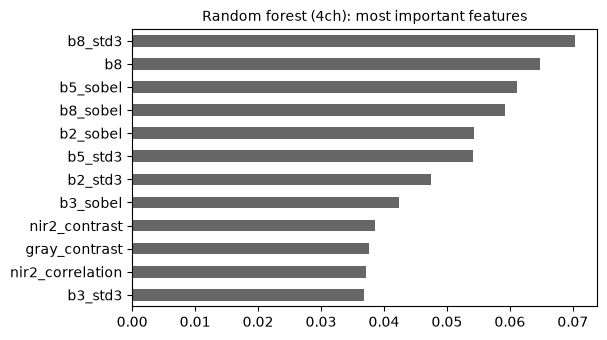

In [ ]:
# Random forest on spectral, gradient and texture features (the paper's baseline).
from rasterio.warp import reproject                       # resample texture layers to 0.5 m
from scipy import ndimage as ndi                          # local filters
from skimage.filters import sobel                         # gradient magnitude
from sklearn.ensemble import RandomForestClassifier

def to_05(a):
    """A 1.6 m feature layer -> the 0.5 m grid (bilinear)."""
    out = np.full((H, W), np.nan, "float32")
    reproject(a.astype("float32"), out, src_transform=TRANSFORM, src_crs=CRS, dst_transform=T05, dst_crs=CRS,
              resampling=Resampling.bilinear, src_nodata=np.nan, dst_nodata=np.nan)
    return np.nan_to_num(out)                             # missing values -> 0

# Texture at the native 1.6 m: local binary patterns and grey-level co-occurrence (GLCM)
# contrast, correlation, entropy and homogeneity in 7 x 7 windows (GeoLattice texture module).
t0 = time.perf_counter()
native = normalise(X8[None])[0]                           # (8, 702, 760) in [0, 1]
tex_src = {"gray": native[[1, 2, 4]].mean(0), "nir2": native[7]}   # mean of blue, green, red; and NIR2
TEX = {}
for nm, img in tex_src.items():
    lbp = texture.lbp_texture(img, radius=1, n_points=8, size=7, step=1)        # LBP uniformity and entropy
    glcm = texture.glcm_texture(img, size=7, step=2, levels=32, props=("contrast", "correlation", "entropy", "homogeneity"))
    for k, v in {**lbp, **glcm}.items():
        TEX[f"{nm}_{k}"] = to_05(np.asarray(v))          # e.g. "gray_contrast" on the 0.5 m grid
print(f"texture layers: {len(TEX)} in {time.perf_counter() - t0:.0f} s")

def rf_features(bands, use_nir_texture):
    """Per-pixel features on the 0.5 m grid: band values, 3x3 local std, Sobel gradient, texture."""
    F = {}
    for b in bands:
        x = SCENE[b]
        F[f"b{b + 1}"] = x                                # the band value
        # Local standard deviation in a 3 x 3 window: sqrt(E[x²] - E[x]²).
        F[f"b{b + 1}_std3"] = np.sqrt(np.maximum(ndi.uniform_filter(x ** 2, 3) - ndi.uniform_filter(x, 3) ** 2, 0))
        F[f"b{b + 1}_sobel"] = sobel(ndi.gaussian_filter(x, 1.0))   # gradient after light smoothing
    F.update({k: v for k, v in TEX.items() if k.startswith("gray") or use_nir_texture})   # NIR texture only for 4ch
    return F

# Train on a balanced sample of training-tile pixels; 600 trees of depth <= 30 as in the paper.
RF = {}
for ch, bands in BANDS.items():
    F = rf_features(bands, use_nir_texture=len(bands) == 4)
    names = list(F)
    stack_tiles = lambda which: np.stack([cut(F[n], which) for n in names], -1)   # (n, 192, 192, f)
    Ft = stack_tiles(idx["train"]); yt = TRUTH[idx["train"]]; okt = SCORED[idx["train"]]
    rng = np.random.default_rng(SEED)
    # Indices of labelled boundary (pos) and field (neg) pixels; 40,000 of each are drawn.
    pos, neg = np.flatnonzero(okt.ravel() & (yt.ravel() == 1)), np.flatnonzero(okt.ravel() & (yt.ravel() == 0))
    pick = np.concatenate([rng.choice(pos, 40_000, replace=False), rng.choice(neg, 40_000, replace=False)])
    t0 = time.perf_counter()
    rf = RandomForestClassifier(n_estimators=600, max_depth=30, n_jobs=-1, random_state=SEED)   # all CPU cores
    rf.fit(Ft.reshape(-1, len(names))[pick], yt.ravel()[pick])
    fit_s = time.perf_counter() - t0
    def rf_scores(split, rf=rf, stack_tiles=stack_tiles):
        # Boundary probability of every pixel of the tiles of one split.
        Fx = stack_tiles(idx[split])
        return rf.predict_proba(Fx.reshape(-1, Fx.shape[-1]))[:, 1].reshape(Fx.shape[:3]).astype("float32")
    cache = {s: rf_scores(s) for s in ("train", "val", "test")}
    evaluate("Random forest", ch, cache.get, kind="2 random forest")
    RF[ch] = {"model": rf, "features": names, "fit_s": fit_s, "scores": cache}
    print(f"{ch}: {len(names)} features, fitted in {fit_s:.0f} s")
display(table().loc["2 random forest"].drop(columns=["field_precision", "field_recall"]))
# The twelve most important features of the 4-channel forest (mean decrease in impurity).
imp = pd.Series(RF["4ch (B, G, R, NIR2)"]["model"].feature_importances_, RF["4ch (B, G, R, NIR2)"]["features"]).sort_values()
imp.tail(12).plot.barh(figsize=(6, 3.6), color="0.4", title="Random forest (4ch): most important features"); plt.show()

## The six networks

All six are built by `ed.build_edge_model`, which accepts `in_channels=3` or `4`:

| Network | Idea | Paper |
|---|---|---|
| **U-Net** | Encoder of 3 x 3 convolutions and max-pools (64 to 1024 filters); the decoder upsamples and concatenates the encoder features at the same scale (skip connections). | Table 2, Fig. 4 |
| **SegNet** | VGG16 encoder (13 convolutions); the decoder upsamples with the **max-pooling indices** saved by the encoder, so no upsampling weights are learnt. | Table 3, Fig. 5 |
| **FC-DenseNet56/67/103** | Dense blocks: each layer receives the feature maps of all previous layers in the block; transition-down and -up between blocks. They differ in depth and growth rate (4, 5 and 4-15 layers per block). | Table 4, Figs. 6-7 |
| **FCN-DKConv6** | Six 5 x 5 dilated convolutions (dilation 1 to 6) with batch normalisation and leaky ReLU; no pooling, so the resolution never drops. | Table 5 |

All are trained with pixel-wise cross-entropy (the softmax loss of the paper), Adam with L2 weight decay 1e-4, dropout and a cosine learning-rate schedule. Pixels outside the digitised area carry the label -100 and are ignored by the loss. SegNet is the exception to the shared settings: it has no skip connections, and on this small training set it only learns the thin boundary class with class-weighted cross-entropy and a longer schedule (`SPECIAL` below).


In [ ]:
# The six networks of the paper, built with geolattice.rsense.edge_detectors.
import json                                # store training histories next to the weights

NETS = {                                   # name -> (edge_detectors model name, keyword arguments)
    "U-Net": ("unet_basic", {"base": 64, "depth": 4, "dropout": 0.5}),   # paper Table 2: 64 ... 1024 filters, dropout 0.5
    "SegNet": ("SegNet", {"dropout_p": 0.5}),                           # Table 3: VGG16 encoder, pooling indices, central dropout
    "FC-DenseNet56": ("FC-DenseNet56", {}),                             # Table 4
    "FC-DenseNet67": ("FC-DenseNet67", {}),
    "FC-DenseNet103": ("FC-DenseNet103", {}),
    "FCN-DKConv6": ("FCN-DKConv6", {}),                                 # Table 5: six dilated 5 x 5 convolutions
}
# Build each network once on the CPU to report its size.
arch_tbl = []
for name, (arch, kw) in NETS.items():
    m = ed.build_edge_model(arch, in_channels=4, device="cpu", **kw)
    arch_tbl.append({"network": name, "GeoLattice model": arch, "parameters (4ch)": f"{ic.count_parameters(m):,}"})
display(pd.DataFrame(arch_tbl).set_index("network"))

TRAIN = {"epochs": 60, "batch": 4, "lr": 1e-3, "weight_decay": 1e-4}   # lr confirmed by the sweep below
NET_DIR = OUT / "models"                                               # trained weights are saved here
NET_DIR.mkdir(exist_ok=True)

# SegNet has no skip connections, and with 180 training tiles it learns to call every pixel
# "non-boundary" under the common settings. It gets class-weighted cross-entropy (boundary weight =
# non-boundary / boundary pixels in the training tiles) and 150 epochs instead of 60.
SHARE = float((Ytr == 1).sum() / (Ytr >= 0).sum())                     # boundary share of labelled training pixels
CLASS_W = torch.tensor([1.0, (1 - SHARE) / SHARE], dtype=torch.float32)
SPECIAL = {"SegNet": {"epochs": 150, "loss": torch.nn.CrossEntropyLoss(weight=CLASS_W, ignore_index=-100)}}
print(f"boundary share of training pixels {SHARE:.3f}; SegNet boundary weight {CLASS_W[1]:.2f}")

def train_net(name, ch, *, epochs=None, lr=None, batch=None, tag=""):
    """Train one network on one band set (or load it if it was trained before) and return
    (model, history, seconds). Cross-entropy, Adam with L2 weight decay, cosine learning-rate
    schedule; the weights of the epoch with the best validation mean IoU are kept."""
    arch, kw = NETS[name]
    bands = BANDS[ch]
    sp = SPECIAL.get(name, {})                                         # network-specific settings, if any
    epochs, lr, batch = epochs or sp.get("epochs", TRAIN["epochs"]), lr or TRAIN["lr"], batch or TRAIN["batch"]
    pt, js = NET_DIR / f"{name}_{len(bands)}ch{tag}.pt", NET_DIR / f"{name}_{len(bands)}ch{tag}.json"
    model = ed.build_edge_model(arch, in_channels=len(bands), device=DEVICE, **kw)
    if pt.exists():                                                    # trained before: load weights and history
        model.load_state_dict(torch.load(pt, map_location=DEVICE))
        meta = json.loads(js.read_text())
        return model.eval(), meta["history"], meta["seconds"]
    ic.set_seed(SEED)
    # Data loaders: shuffled augmented training tiles, and the validation tiles in order.
    train_dl = ic.as_loader(ic.ChipDataset(Xtr[:, bands], Ytr), batch, shuffle=True, seed=SEED)
    val_dl = ic.as_loader(ic.ChipDataset(X_all[idx["val"]][:, bands], Y_all[idx["val"]]), 8, shuffle=False)
    t0 = time.perf_counter()
    hist = ic.train_model(model, train_dl, val_dl, task="segmentation", epochs=epochs, loss=sp.get("loss", "ce"),
                          optimizer="adam", lr=lr, weight_decay=TRAIN["weight_decay"], scheduler="cosine",
                          num_classes=2, ignore_index=-100, monitor="val_score", device=DEVICE,
                          seed=SEED, verbose=False)
    seconds = time.perf_counter() - t0
    torch.save(model.state_dict(), pt)                                 # save weights and history for re-runs
    js.write_text(json.dumps({"history": hist, "seconds": seconds, "epochs": epochs, "lr": lr}))
    return model.eval(), hist, seconds

def net_scores(model, ch, split):
    """Boundary probability of every tile of a split (softmax of class 1)."""
    p = ic.predict_proba_batches(model, X_all[idx[split]][:, BANDS[ch]], batch_size=8, device=DEVICE)
    return p[:, 1].astype("float32")

,GeoLattice model,parameters (4ch)
network,,
U-Net,unet_basic,"31,038,274"
SegNet,SegNet,"29,472,770"
FC-DenseNet56,FC-DenseNet56,"1,375,490"
FC-DenseNet67,FC-DenseNet67,"3,461,074"
FC-DenseNet103,FC-DenseNet103,"9,320,210"
FCN-DKConv6,FCN-DKConv6,"117,218"


boundary share of training pixels 0.107; SegNet boundary weight 8.36


### Learning-rate sensitivity

The paper tuned learning rate, batch size, image size, patch size and dropout (Table 6) and settled on 1e-4 with batch size 1 and 500 epochs. With a 30-epoch budget, the three learning rates compare as follows on the validation tiles:


In [ ]:
# Learning-rate sensitivity (cf. paper Table 6), FC-DenseNet56 with 4 channels, 30 epochs.
sweep = []
for lr in (1e-2, 1e-3, 1e-4):
    model, hist, sec = train_net("FC-DenseNet56", "4ch (B, G, R, NIR2)", epochs=30, lr=lr, tag=f"_lr{lr:.0e}")
    s_val = net_scores(model, "4ch (B, G, R, NIR2)", "val")             # validation boundary probabilities
    th, _ = ed.select_threshold(s_val, TRUTH[idx["val"]], valid=SCORED[idx["val"]])   # best validation threshold
    m = ed.edge_metrics(s_val, TRUTH[idx["val"]], threshold=th, valid=SCORED[idx["val"]])
    sweep.append({"learning rate": lr, "best val mIoU": max(hist["val_score"]), "val boundary F1": m["boundary_f1"],
                  "val AUC": m["auc"], "minutes": sec / 60})
    del model; torch.cuda.empty_cache()                                 # free GPU memory before the next run
display(pd.DataFrame(sweep).set_index("learning rate").round(3))

,best val mIoU,val boundary F1,val AUC,minutes
learning rate,,,,
0.0100,0.533,0.460,0.817,1.907
0.0010,0.549,0.452,0.807,1.999
0.0001,0.470,0.360,0.748,1.971


After 30 epochs, 1e-2 and 1e-3 end close together (validation mean IoU 0.53 and 0.55, boundary F1 0.46 and 0.45). 1e-4, the paper's choice, is still well behind (0.47 and 0.36): it needs the paper's much longer schedule. The networks below use 1e-3 for 60 epochs.


### Training on 3 and 4 channels


In [ ]:
# Train the six networks on both band sets and score them (about 50 min on one GPU;
# re-runs load the saved weights from outputs/field_edge_worldview/models).
MODELS, HIST, SECONDS = {}, {}, {}
for ch in BANDS:                                                        # 3 and 4 channels
    for name in NETS:                                                   # six networks
        model, hist, sec = train_net(name, ch)
        MODELS[(name, ch)], HIST[(name, ch)], SECONDS[(name, ch)] = model, hist, sec
        cache = {s: net_scores(model, ch, s) for s in ("train", "val", "test")}
        th = evaluate(name, ch, cache.get, kind="3 network")            # threshold chosen on validation
        last = [r for r in RESULTS if r["method"] == name and r["channels"] == ch and r["split"] == "test"][-1]
        print(f"{name:15s} {ch:20s} {sec / 60:5.1f} min | threshold {th:.2f} | test boundary F1 {last['boundary_f1']:.3f}, AUC {last['auc']:.3f}")

U-Net           3ch (B, G, R)          2.9 min | threshold 0.25 | test boundary F1 0.460, AUC 0.859


SegNet          3ch (B, G, R)          6.8 min | threshold 0.55 | test boundary F1 0.317, AUC 0.742


FC-DenseNet56   3ch (B, G, R)          4.2 min | threshold 0.20 | test boundary F1 0.414, AUC 0.847


FC-DenseNet67   3ch (B, G, R)          7.7 min | threshold 0.20 | test boundary F1 0.417, AUC 0.866


FC-DenseNet103  3ch (B, G, R)          6.9 min | threshold 0.25 | test boundary F1 0.415, AUC 0.853


FCN-DKConv6     3ch (B, G, R)          1.1 min | threshold 0.25 | test boundary F1 0.450, AUC 0.862


... (2 outputs left out)

FC-DenseNet56   4ch (B, G, R, NIR2)    4.0 min | threshold 0.25 | test boundary F1 0.456, AUC 0.868


FC-DenseNet67   4ch (B, G, R, NIR2)    7.5 min | threshold 0.10 | test boundary F1 0.425, AUC 0.865


FC-DenseNet103  4ch (B, G, R, NIR2)    6.9 min | threshold 0.30 | test boundary F1 0.446, AUC 0.867


FCN-DKConv6     4ch (B, G, R, NIR2)    1.1 min | threshold 0.25 | test boundary F1 0.462, AUC 0.870


## Results

### Tables 7 and 8: precision, recall and F1 for boundary and field

The paper's layout: training tiles (with which the model was fitted) and held-out test tiles, for 3 channels (Table 7) and 4 channels (Table 8).


In [ ]:
# Results in the layout of the paper's Tables 7 (3 channels) and 8 (4 channels).
ORDER = ["Random forest", "FCN-DKConv6", "U-Net", "SegNet", "FC-DenseNet56", "FC-DenseNet67", "FC-DenseNet103"]
df = pd.DataFrame(RESULTS)
df = df[df.tolerance_px == 0]                                           # pixel-exact scores only

def paper_table(ch):
    # Training and test rows of every model, boundary and field columns, as in the paper.
    t = df[(df.channels == ch) & df.split.isin(["train", "test"]) & df.method.isin(ORDER)]
    t = t.set_index(["split", "method"])[["boundary_precision", "boundary_recall", "boundary_f1",
                                          "field_precision", "field_recall", "field_f1"]]
    t.columns = pd.MultiIndex.from_tuples([("Boundary", "Precision"), ("Boundary", "Recall"), ("Boundary", "F1"),
                                           ("Field (cropland)", "Precision"), ("Field (cropland)", "Recall"), ("Field (cropland)", "F1")])
    return t.reindex([(s, m) for s in ("train", "test") for m in ORDER]).round(2)

for ch in BANDS:
    print(f"\n{ch}: training and held-out test tiles (threshold chosen on validation tiles)")
    display(paper_table(ch))

# All methods on the test tiles, 3 vs 4 channels.
test = df[df.split == "test"].pivot_table(index=["kind", "method"], columns="channels", values=["boundary_f1", "auc"], sort=False)
# Gain from adding NIR2: 4-channel score minus 3-channel score.
test[("boundary_f1", "gain 4ch - 3ch")] = test[("boundary_f1", "4ch (B, G, R, NIR2)")] - test[("boundary_f1", "3ch (B, G, R)")]
test[("auc", "gain 4ch - 3ch")] = test[("auc", "4ch (B, G, R, NIR2)")] - test[("auc", "3ch (B, G, R)")]
display(test.sort_index(axis=1).round(3))


3ch (B, G, R): training and held-out test tiles (threshold chosen on validation tiles)


Boundary              Field (cropland)             
                     Precision Recall    F1        Precision Recall    F1
split method                                                             
train Random forest       0.42   0.63  0.50             0.95   0.89  0.92
      FCN-DKConv6         0.51   0.78  0.61             0.97   0.91  0.94
      U-Net               0.61   0.83  0.70             0.98   0.94  0.96
      SegNet              0.30   0.44  0.36             0.93   0.88  0.90
      FC-DenseNet56       0.52   0.84  0.64             0.98   0.91  0.94
      FC-DenseNet67       0.51   0.84  0.63             0.98   0.90  0.94
      FC-DenseNet103      0.49   0.79  0.60             0.97   0.90  0.94
test  Random forest       0.29   0.45  0.36             0.95   0.91  0.93
      FCN-DKConv6         0.37   0.58  0.45             0.96   0.92  0.94
      U-Net               0.39   0.55  0.46             0.96   0.93  0.95
      SegNet              0.25   0.44  0.32             0.95   0.89  0.92
      FC-DenseNet56       0.32   0.58  0.41             0.96   0.90  0.93
      FC-DenseNet67       0.31   0.63  0.42             0.97   0.88  0.92
      FC-DenseNet103      0.32   0.59  0.42             0.96   0.90  0.93


4ch (B, G, R, NIR2): training and held-out test tiles (threshold chosen on validation tiles)


Boundary              Field (cropland)             
                     Precision Recall    F1        Precision Recall    F1
split method                                                             
train Random forest       0.41   0.75  0.53             0.97   0.87  0.92
      FCN-DKConv6         0.53   0.79  0.63             0.97   0.92  0.94
      U-Net               0.62   0.87  0.72             0.98   0.94  0.96
      SegNet              0.25   0.66  0.36             0.95   0.76  0.84
      FC-DenseNet56       0.52   0.73  0.61             0.97   0.92  0.94
      FC-DenseNet67       0.52   0.91  0.66             0.99   0.90  0.94
      FC-DenseNet103      0.56   0.79  0.66             0.97   0.93  0.95
test  Random forest       0.29   0.48  0.36             0.95   0.90  0.93
      FCN-DKConv6         0.38   0.59  0.46             0.96   0.92  0.94
      U-Net               0.38   0.56  0.45             0.96   0.92  0.94
      SegNet              0.20   0.53  0.29             0.96   0.82  0.88
      FC-DenseNet56       0.38   0.58  0.46             0.96   0.92  0.94
      FC-DenseNet67       0.32   0.62  0.42             0.97   0.89  0.93
      FC-DenseNet103      0.36   0.58  0.45             0.96   0.91  0.94

auc                      \
channels                              3ch (B, G, R) 4ch (B, G, R, NIR2)   
kind            method                                                    
1 classical     Roberts                       0.718               0.754   
                Sobel                         0.738               0.768   
                Prewitt                       0.739               0.768   
                Laplacian of Gaussian         0.659               0.700   
                Canny                         0.564               0.593   
2 random forest Random forest                 0.767               0.790   
3 network       U-Net                         0.859               0.869   
                SegNet                        0.742               0.756   
                FC-DenseNet56                 0.847               0.868   
                FC-DenseNet67                 0.866               0.865   
                FC-DenseNet103                0.853               0.867   
                FCN-DKConv6                   0.862               0.870   

                                                       boundary_f1  \
channels                              gain 4ch - 3ch 3ch (B, G, R)   
kind            method                                               
1 classical     Roberts                        0.036         0.315   
                Sobel                          0.029         0.334   
                Prewitt                        0.029         0.335   
                Laplacian of Gaussian          0.041         0.237   
                Canny                          0.029         0.204   
2 random forest Random forest                  0.023         0.356   
3 network       U-Net                          0.010         0.460   
                SegNet                         0.014         0.317   
                FC-DenseNet56                  0.021         0.414   
                FC-DenseNet67                 -0.001         0.417   
                FC-DenseNet103                 0.014         0.415   
                FCN-DKConv6                    0.008         0.450   

                                                                          
channels                              4ch (B, G, R, NIR2) gain 4ch - 3ch  
kind            method                                                    
1 classical     Roberts                             0.320          0.005  
                Sobel                               0.364          0.030  
                Prewitt                             0.364          0.030  
                Laplacian of Gaussian               0.277          0.040  
                Canny                               0.249          0.045  
2 random forest Random forest                       0.360          0.004  
3 network       U-Net                               0.453         -0.007  
                SegNet                              0.288         -0.029  
                FC-DenseNet56                       0.456          0.042  
                FC-DenseNet67                       0.425          0.008  
                FC-DenseNet103                      0.446          0.031  
                FCN-DKConv6                         0.462          0.011

**Test tiles, boundary class.**

- All networks except SegNet reach a boundary F1 of **0.41 to 0.46**. The random forest reaches 0.36, and the traditional detectors 0.20 to 0.36 (Sobel and Prewitt are best, Canny worst).
- With 3 channels the best network is U-Net (0.46). With 4 channels FCN-DKConv6, FC-DenseNet56 and U-Net are tied at 0.45 to 0.46.
- SegNet is the weakest network (0.32 and 0.29), below the random forest.
- The field (cropland) class is easy for every method: F1 0.88 to 0.95, because it covers about 90 % of the scored pixels.

**Training tiles vs test tiles.** U-Net drops from F1 0.70 on its training tiles to 0.46 on the test tiles, and the FC-DenseNets from about 0.60 to 0.42. With only 45 training tiles, part of what the networks learn does not carry over to unseen fields.

**RGB vs RGB + NIR (last table).**

- **Traditional detectors gain the most.** AUC rises by 0.03 to 0.04 for every detector, and F1 by 0.03 to 0.05 (Roberts only +0.005). In the near infrared, the bare or grassy bunds contrast more strongly with the crop.
- **The random forest** gains 0.02 AUC, with F1 unchanged.
- **The networks gain little and not consistently.** AUC changes by -0.001 to +0.021. F1 changes by -0.03 (SegNet) to +0.04 (FC-DenseNet56), and U-Net is slightly lower with NIR. The networks seem to learn the bund pattern from the shape and texture of RGB, so the extra band adds little.

### Learning curves and training time (paper Figs. 8 and 9)


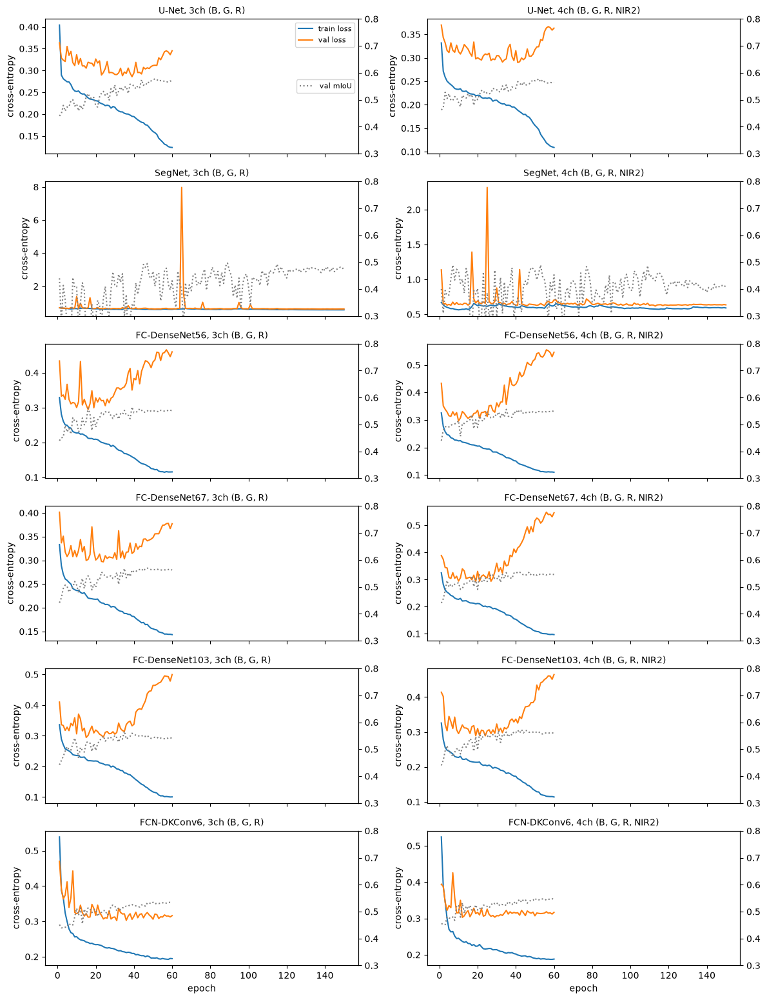

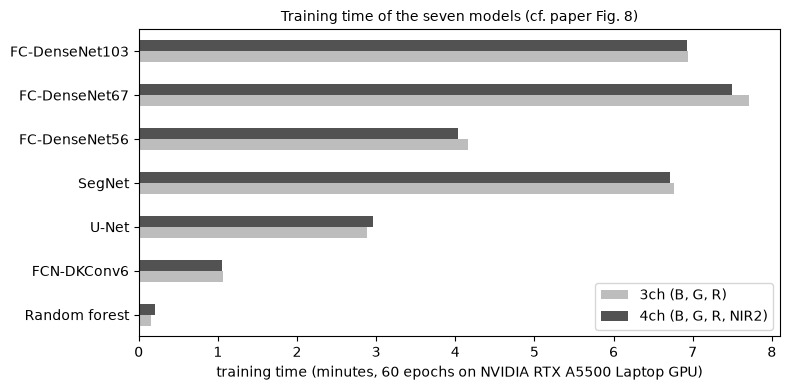

In [ ]:
# Learning curves (cf. paper Fig. 9) and training time (cf. Fig. 8).
nets = list(NETS)
fig, ax = plt.subplots(len(nets), 2, figsize=(12, 2.6 * len(nets)), sharex=True)   # one row per network, one column per band set
for i, name in enumerate(nets):
    for j, ch in enumerate(BANDS):
        h = HIST[(name, ch)]                                       # per-epoch training history
        ep = np.arange(1, len(h["train_loss"]) + 1)
        ax[i, j].plot(ep, h["train_loss"], label="train loss"); ax[i, j].plot(ep, h["val_loss"], label="val loss")
        # Validation mean IoU on a second y-axis (dotted grey).
        a2 = ax[i, j].twinx(); a2.plot(ep, h["val_score"], color="0.5", ls=":", label="val mIoU"); a2.set_ylim(0.3, 0.8)
        ax[i, j].set_title(f"{name}, {ch}"); ax[i, j].set_ylabel("cross-entropy")
        if i == 0 and j == 0:                                      # one legend is enough
            ax[i, j].legend(loc="upper right", fontsize=8); a2.legend(loc="center right", fontsize=8)
for a in ax[-1]:
    a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

# Training time in minutes of the random forest and the six networks, for both band sets.
times = pd.DataFrame({ch: {**{"Random forest": RF[ch]["fit_s"] / 60}, **{n: SECONDS[(n, ch)] / 60 for n in nets}}
                      for ch in BANDS}).loc[ORDER]
ax = times.plot.barh(figsize=(8, 4), color=["#bdbdbd", "#525252"])
ax.set_xlabel(f"training time (minutes, {TRAIN['epochs']} epochs on {torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU'})")
ax.set_title("Training time of the seven models (cf. paper Fig. 8)"); plt.tight_layout(); plt.show()

**Learning curves (Fig. 9 equivalent).**

- **U-Net and the three FC-DenseNets** reach their lowest validation loss between epochs 20 and 35. After that, training loss keeps falling while validation loss rises: they over-fit the 180 training tiles. Validation mean IoU levels off near 0.55 to 0.60. Because the weights of the best validation epoch are kept, the over-fitting does not reach the scores above.
- **FCN-DKConv6** (117 k parameters) has a flat validation loss and does not over-fit.
- **SegNet's** curves are noisy with spikes; its validation mean IoU wanders between 0.3 and 0.5.

**Training time (Fig. 8 equivalent), one RTX A5500 GPU, 60 epochs.**

| Model | Training time |
|---|---|
| FCN-DKConv6 | 1.1 min |
| U-Net | 3 min |
| FC-DenseNet56 | 4 min |
| FC-DenseNet103 | 6.9 min |
| FC-DenseNet67 | 7.5 min |
| SegNet (150 epochs) | 6.8 min |
| Random forest | about 10 s to fit, plus about 1 min for the texture features |

As in the paper, the dense networks are slow for their parameter count, because every layer concatenates all earlier feature maps.

### ROC curves on the test tiles (paper Fig. 10)


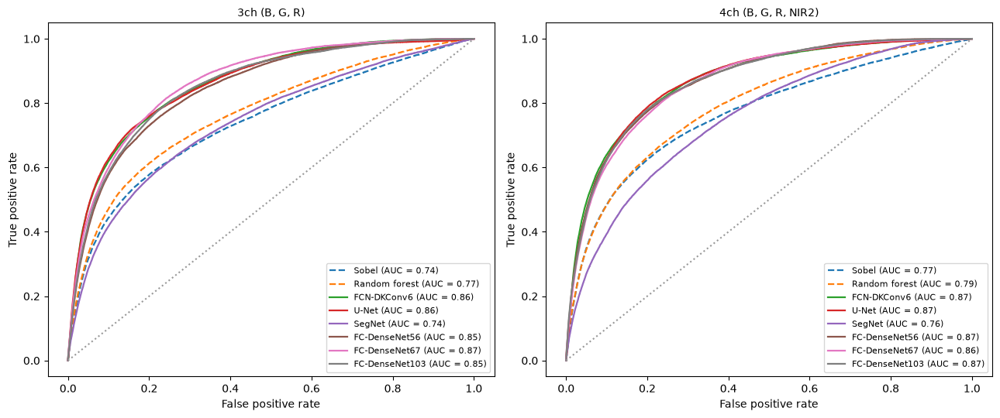

In [ ]:
# ROC curves on the test tiles (cf. paper Fig. 10).
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))                    # 3 channels left, 4 channels right
show = ["Sobel", "Random forest", "FCN-DKConv6", "U-Net", "SegNet", "FC-DenseNet56", "FC-DenseNet67", "FC-DenseNet103"]
for a, ch in zip(ax, BANDS):
    for name in show:
        fpr, tpr, auc = CURVES[(name, ch)]                         # stored by evaluate() for the test tiles
        # Dashed lines for the two non-network baselines.
        a.plot(fpr, tpr, lw=1.6, ls="--" if name in ("Sobel", "Random forest") else "-", label=f"{name} (AUC = {auc:.2f})")
    a.plot([0, 1], [0, 1], color="0.6", ls=":")                    # the diagonal = random guessing
    a.set_xlabel("False positive rate"); a.set_ylabel("True positive rate"); a.set_title(ch); a.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**Test-tile AUC.**

| Method | AUC |
|---|---|
| Networks, except SegNet | 0.85 to 0.87 |
| SegNet | 0.74 to 0.76 |
| Random forest | 0.77 to 0.79 |
| Sobel and Prewitt | 0.74 to 0.77 |
| Canny | 0.56 to 0.59 |

Canny returns a binary map, so its ROC curve has a single operating point. For every method the 4-channel curve lies on or slightly above the 3-channel curve.

### Predicted boundaries on training, validation and test tiles (paper Fig. 11)


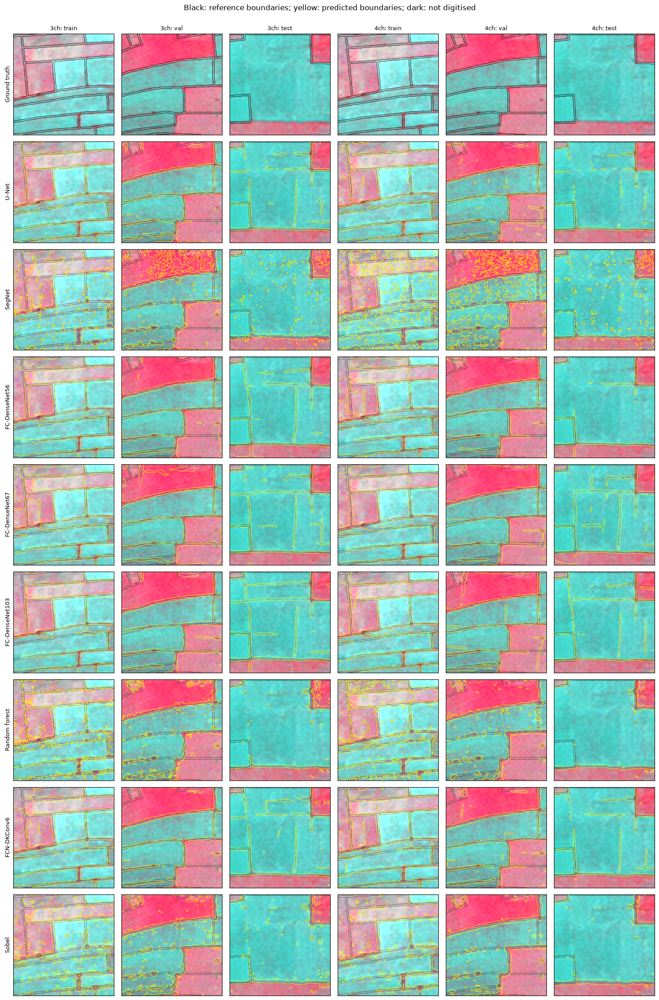

In [ ]:
# Predicted boundaries on one training, one validation and one test tile (cf. paper Fig. 11).
pick = {s: int(np.argmax(SCORED[idx[s]].mean((1, 2)))) for s in ("train", "val", "test")}   # best-labelled tile per split
rows = ["Ground truth", "U-Net", "SegNet", "FC-DenseNet56", "FC-DenseNet67", "FC-DenseNet103", "Random forest", "FCN-DKConv6", "Sobel"]
thr = df[df.split == "test"].set_index(["method", "channels"])["threshold"]   # each method's validation threshold
fig, ax = plt.subplots(len(rows), 6, figsize=(15, 2.5 * len(rows)))
# Six columns: (3ch, 4ch) x (train, val, test).
for j, (ch, split) in enumerate([(c, s) for c in BANDS for s in ("train", "val", "test")]):
    k = pick[split]
    tile_fc = false_colour(X_all[idx[split]][k], lo=0, hi=1)      # tiles are already normalised to [0, 1]
    ok = SCORED[idx[split]][k]
    for i, name in enumerate(rows):
        a = ax[i, j]
        a.imshow(np.where(ok[..., None], tile_fc, tile_fc * 0.35))  # darken pixels that were not digitised
        if name == "Ground truth":
            a.contour(TRUTH[idx[split]][k], levels=[0.5], colors="black", linewidths=0.6)
        else:
            pred = SCORES[(name, ch, split)][k] >= thr[(name, ch)]  # predicted boundary pixels
            a.contour(TRUTH[idx[split]][k], levels=[0.5], colors="black", linewidths=0.3)
            a.contour(pred.astype(float), levels=[0.5], colors="yellow", linewidths=0.6)
        a.set_xticks([]); a.set_yticks([])
        if i == 0:
            a.set_title(f"{ch.split(' ')[0]}: {split}", fontsize=9)
        if j == 0:
            a.set_ylabel(name, fontsize=9)
fig.suptitle("Black: reference boundaries; yellow: predicted boundaries; dark: not digitised", y=1.0)
plt.tight_layout(); plt.show()

The networks other than SegNet draw thin, mostly continuous lines along the bunds, including on the validation and test tiles. Sobel and the random forest find the same lines but break them up and also respond to texture inside fields. SegNet produces speckle, especially inside the red (densely vegetated) fields.

On the test tile, the networks draw straight lines across the large field where faint bunds are visible in the image but were not digitised. These lines count as false positives, so the precision of the networks is probably understated.

### How strict is pixel-exact scoring?

The reference boundary is a 1 m band drawn by hand on a 1.6 m image. A prediction one pixel (0.5 m) to the side counts as both a false positive and a false negative. With a tolerance of 0.5 m or 1 m, a predicted boundary pixel counts as correct when a reference boundary lies within that distance, and vice versa:


In [ ]:
# How strict is pixel-exact scoring? Test F1 with a 0.5 m and 1 m positional tolerance.
rows = []
for (name, ch, split), s in SCORES.items():
    if split != "test" or ch != "4ch (B, G, R, NIR2)" or name not in ORDER + ["Sobel"]:   # 4-channel test tiles only
        continue
    for tol in (0, 1, 2):                                          # 0, 1 and 2 pixels = 0, 0.5 and 1 m
        m = ed.edge_metrics(s, TRUTH[idx["test"]], threshold=thr[(name, ch)], valid=SCORED[idx["test"]], tolerance=tol)
        rows.append({"method": name, "tolerance": f"{tol * GSD:g} m", "boundary F1": m["boundary_f1"]})
tol_tbl = pd.DataFrame(rows).pivot(index="method", columns="tolerance", values="boundary F1").loc[["Sobel"] + ORDER]
display(tol_tbl.round(3))

tolerance,0 m,0.5 m,1 m
method,,,
Sobel,0.364,0.516,0.619
Random forest,0.360,0.510,0.613
FCN-DKConv6,0.462,0.627,0.715
U-Net,0.453,0.625,0.720
SegNet,0.288,0.426,0.529
FC-DenseNet56,0.456,0.618,0.705
FC-DenseNet67,0.425,0.575,0.662
FC-DenseNet103,0.446,0.609,0.692


**Effect of positional tolerance on F1.**

- A tolerance of 0.5 m (one pixel) raises boundary F1 by about 0.16 for every method; 1 m raises it by about 0.26.
- At 1 m tolerance the networks reach 0.66 to 0.72 (SegNet 0.53), Sobel 0.62 and the random forest 0.61.
- The ranking does not change.

Much of the remaining error at zero tolerance is a correct line that is one or two pixels to the side. That is expected when a 1.6 m image is resampled to 0.5 m and compared with a hand-drawn 1 m band.


## From boundary probability to field polygons

`ed.detect_field_edges` runs the best network over the whole scene in overlapping 192 x 192 windows (blended with a Hann weight, so tile seams disappear), thresholds the probability, and turns the connected non-boundary regions into fields (`ed.boundary_to_instances`), returned as georeferenced polygons with area and perimeter.


best on validation: U-Net, 3ch (B, G, R) (val boundary F1 0.494, threshold 0.25)


scene inference + polygons in 11 s: 600 fields


,fields,median area (ha),mean area (ha)
digitised,567.0,0.070,0.122
U-Net (3ch),349.0,0.057,0.159


digitised fields matched by a predicted field with IoU >= 0.5: 38% (>= 0.7: 20%); median best IoU 0.34


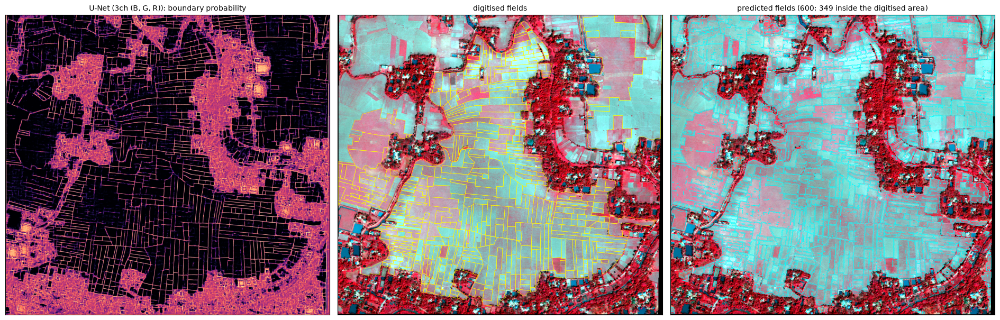

In [ ]:
# From boundary probability to georeferenced field polygons for the whole scene.
from rasterio.features import rasterize

# Best network by validation boundary F1 (both band sets), applied to the full scene with
# overlapping 192 x 192 windows blended by a Hann weight (ed.predict_boundary_probability,
# called inside ed.detect_field_edges).
val = df[(df.split == "val") & (df.kind == "3 network")].sort_values("boundary_f1", ascending=False)
best_name, best_ch = val.iloc[0][["method", "channels"]]
best_th = float(thr[(best_name, best_ch)])
print(f"best on validation: {best_name}, {best_ch} (val boundary F1 {val.iloc[0]['boundary_f1']:.3f}, threshold {best_th:.2f})")
scene_img = np.moveaxis(SCENE[BANDS[best_ch]], 0, -1)              # (H, W, bands) of the whole scene
t0 = time.perf_counter()
# Probability, threshold, closed regions and polygons of at least 50 m², in map coordinates.
res = ed.detect_field_edges(scene_img, MODELS[(best_name, best_ch)], transform=T05, crs=CRS, threshold=best_th,
                            min_area_m2=50, dilate_pixels=1, tile_size=TILE, overlap=64, batch_size=8, device=DEVICE)
print(f"scene inference + polygons in {time.perf_counter() - t0:.0f} s: {len(res.fields)} fields")

# Compare with the digitised fields inside the digitised area: count, size and overlap.
area_poly = fields.union_all()                                     # the digitised area as one polygon
pred = res.fields[res.fields.representative_point().within(area_poly)].copy()   # predicted fields inside it
# Intersections of every digitised field with every predicted field, and their areas.
inter = gpd.overlay(fields[["geometry"]].reset_index(names="ref"), pred[["field_id", "geometry"]], how="intersection")
inter["a"] = inter.area
best_overlap = inter.sort_values("a").groupby("ref").last()       # largest overlap per digitised field
# IoU of each digitised field with its best-overlapping predicted field.
iou = best_overlap.apply(lambda r: r.a / fields.geometry[r.name].union(pred.set_index("field_id").geometry[r.field_id]).area, axis=1)
summary = pd.DataFrame({
    "digitised": {"fields": len(fields), "median area (ha)": fields.area.median() / 1e4, "mean area (ha)": fields.area.mean() / 1e4},
    f"{best_name} ({best_ch.split(' ')[0]})": {"fields": len(pred), "median area (ha)": pred.area.median() / 1e4,
                                               "mean area (ha)": pred.area.mean() / 1e4}}).T
display(summary.round(3))
print(f"digitised fields matched by a predicted field with IoU >= 0.5: {(iou >= 0.5).mean():.0%} "
      f"(>= 0.7: {(iou >= 0.7).mean():.0%}); median best IoU {iou.median():.2f}")

# Save the probability raster and the polygons.
with rasterio.open(OUT / "boundary_probability.tif", "w", driver="GTiff", height=H, width=W, count=1, dtype="float32",
                   crs=CRS, transform=T05, compress="deflate") as dst:
    dst.write(res.probability.astype("float32"), 1)
res.fields.to_file(OUT / "predicted_fields.gpkg", layer="fields", driver="GPKG")

# Probability map, digitised fields and predicted fields side by side.
fig, ax = plt.subplots(1, 3, figsize=(19, 6.4))
ax[0].imshow(res.probability, cmap="magma", vmin=0, vmax=1, extent=EXT); ax[0].set_title(f"{best_name} ({best_ch}): boundary probability")
ax[1].imshow(FC, extent=EXT); fields.boundary.plot(ax=ax[1], color="yellow", lw=0.4); ax[1].set_title("digitised fields")
ax[2].imshow(FC, extent=EXT); res.fields.boundary.plot(ax=ax[2], color="cyan", lw=0.4)
ax[2].set_title(f"predicted fields ({len(res.fields)}; {len(pred)} inside the digitised area)")
for a in ax:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**Model.** The model with the best validation F1, U-Net with 3 channels, was applied to the whole scene. It took 11 s, including polygonising.

**Counts and sizes.** It produced 600 fields, 349 of them inside the digitised area, against 567 digitised fields. The median area is 0.057 ha, against 0.070 ha for the digitised fields.

**Matching.** 38 % of digitised fields have a predicted field with IoU of at least 0.5, and 20 % have one with IoU of at least 0.7. The median best IoU is 0.34.

**Why the matches are poor.** Fields are built from closed boundary rings, so one gap in a bund line merges two neighbouring fields; this is why the mean predicted area (0.159 ha) is larger. A spurious line splits a field in two. The probability map (left) shows clean lines across the cropland, which is a better result than the polygon scores suggest. Homesteads and tree cover outside the cropland also get high boundary probability, so a real application would mask them with a cropland map first.


## Comparison with the published results


,paper F1 3ch,here F1 3ch,paper F1 4ch,here F1 4ch,paper AUC 3ch,here AUC 3ch,paper AUC 4ch,here AUC 4ch
Random forest,0.29,0.36,0.30,0.36,0.51,0.77,0.53,0.79
FCN-DKConv6,0.56,0.45,0.61,0.46,0.72,0.86,0.74,0.87
U-Net,0.65,0.46,0.65,0.45,0.80,0.86,0.80,0.87
SegNet,0.66,0.32,0.71,0.29,0.82,0.74,0.83,0.76
FC-DenseNet56,0.74,0.41,0.74,0.46,0.85,0.85,0.85,0.87
FC-DenseNet67,0.76,0.42,0.76,0.42,0.86,0.87,0.87,0.86
FC-DenseNet103,0.77,0.42,0.78,0.45,0.88,0.85,0.89,0.87


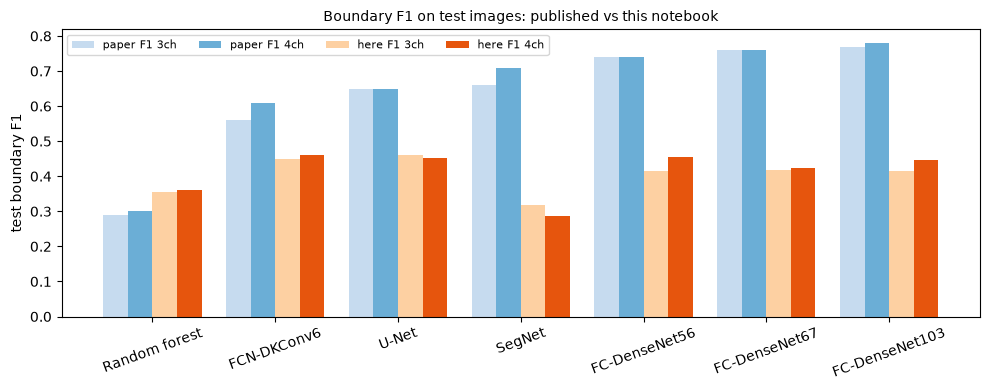

In [ ]:
# This replication next to the published numbers (Yang et al. 2020, Tables 7-8 and Fig. 10, test images).
# Published test boundary F1 and AUC, in the order of ORDER.
paper = pd.DataFrame({
    "paper F1 3ch": [0.29, 0.56, 0.65, 0.66, 0.74, 0.76, 0.77], "paper F1 4ch": [0.30, 0.61, 0.65, 0.71, 0.74, 0.76, 0.78],
    "paper AUC 3ch": [0.51, 0.72, 0.80, 0.82, 0.85, 0.86, 0.88], "paper AUC 4ch": [0.53, 0.74, 0.80, 0.83, 0.85, 0.87, 0.89]},
    index=ORDER)
t = df[df.split == "test"].set_index(["method", "channels"])
# The same four columns from this notebook's test results.
mine = pd.DataFrame({"here F1 3ch": t.xs("3ch (B, G, R)", level=1).boundary_f1, "here F1 4ch": t.xs("4ch (B, G, R, NIR2)", level=1).boundary_f1,
                     "here AUC 3ch": t.xs("3ch (B, G, R)", level=1).auc, "here AUC 4ch": t.xs("4ch (B, G, R, NIR2)", level=1).auc})
cmp_tbl = paper.join(mine)[["paper F1 3ch", "here F1 3ch", "paper F1 4ch", "here F1 4ch",
                            "paper AUC 3ch", "here AUC 3ch", "paper AUC 4ch", "here AUC 4ch"]]
display(cmp_tbl.round(2))

# Grouped bars: four F1 columns per model.
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(ORDER)); w = 0.2
for k, (col, c) in enumerate([("paper F1 3ch", "#c6dbef"), ("paper F1 4ch", "#6baed6"), ("here F1 3ch", "#fdd0a2"), ("here F1 4ch", "#e6550d")]):
    ax.bar(x + (k - 1.5) * w, cmp_tbl[col], w, color=c, label=col)   # shift each column sideways
ax.set_xticks(x); ax.set_xticklabels(ORDER, rotation=20); ax.set_ylabel("test boundary F1"); ax.legend(ncol=4, fontsize=8)
ax.set_title("Boundary F1 on test images: published vs this notebook"); plt.tight_layout(); plt.show()

## Discussion

### What reproduces and what does not

- **Ranking.** As in the paper, deep networks beat the random forest and traditional edge detectors, and the boundary class, not overall accuracy, separates the methods.
- **Absolute F1.** The networks reach 0.41 to 0.46, against 0.56 to 0.78 in the paper.
- **AUC.** AUC is close to the paper's, and higher for the random forest (0.77 to 0.79 vs 0.51 to 0.53), FCN-DKConv6 and U-Net.

### Why F1 is lower

1. **The split.** Here no rotated copy of a test tile is in the training set; in the paper's split, test tiles were rotations of training tiles.
2. **Training budget.** 60 epochs instead of 500.
3. **Image resolution.** A 1.6 m image instead of 1.24 m, so a 1 m wide bund is less than one image pixel.
4. **Training data.** 45 training tiles.

The tolerance analysis shows that about half of the F1 that is missing at zero tolerance comes back within 1 m, so it is positional.

### Points that do not reproduce

- **FC-DenseNet depth.** The paper's order FC-DenseNet56 < 67 < 103 does not appear. On 15 test tiles from one village, differences of 0.04 F1 are within the noise.
- **SegNet.** It was among the better networks in the paper but is the weakest here. Without skip connections it must rebuild thin lines from 6 x 6 feature maps, which takes more data and epochs than this set provides.

### RGB vs RGB + NIR

- **Traditional detectors and the random forest.** Adding NIR2 helps them consistently, because they rely on per-pixel contrast and the bunds are more distinct from the crop in the near infrared.
- **Networks.** The gain is small and not consistent. The paper reports a similar pattern: Tables 7 and 8 differ by 0.00 to 0.05 F1.
- **Practical consequence.** A network trained on RGB alone is close to the 4-band one, so RGB imagery, such as aerial or drone photographs or Google screenshots (see notebook 09_10_02), is a usable input.

### Limitations

- **One small scene.** 71 tiles, and a test set of 15 tiles from one village area. The confidence in any single number is limited. A second site, or cross-validation over blocks, would show how stable the ranking is.
- **The reference.** Hand-digitised outlines on a 1.6 m image with 1 m buffers. Some real bunds were not digitised, and some digitised lines are a pixel or two off. Both effects lower precision and recall for every method alike (see *How strict is pixel-exact scoring?*).
- **Training budget.** 60 (SegNet 150) epochs instead of 500. The learning curves show whether a network was still improving.
- **Not scored outside the fields.** Villages, ponds and roads were not digitised. The scene map (*From boundary probability to field polygons*) shows what the networks do there, but it is not scored.

### Summary

- **Pipeline.** The paper's experiment was rebuilt on the WorldView scene with GeoLattice:
  - `ed.rasterize_boundaries` for labels from the 0.5 m buffer;
  - `ed.tile_pairs` for 192 px tiles;
  - a block split before augmentation;
  - `ed.dihedral_augment` for rotations;
  - `ed.classical_edges` for the traditional detectors;
  - `ed.build_edge_model` for U-Net, SegNet, FC-DenseNet56/67/103 and FCN-DKConv6;
  - `ed.edge_metrics` and `ed.select_threshold` for the paper's metrics.
- **Test boundary F1.** Networks 0.41 to 0.46, random forest 0.36, best traditional detector (Sobel) 0.33 to 0.36. Network AUC is 0.85 to 0.87.
- **NIR.** It helps the traditional detectors (+0.03 to 0.04 AUC) and the random forest (+0.02 AUC), but the networks hardly need it.
- **Lower F1 than the paper** is mostly explained by the leak-free split, a shorter schedule and a coarser image.
- **Small networks are enough.** FCN-DKConv6, with 117 k parameters and 1 minute of training, matches U-Net and FC-DenseNet103 (80 to 265 times larger) on this data.
- **Next steps.** A cropland mask, more digitised tiles, and gap closing before polygonising would turn the good probability maps into usable field polygons.

### References

- Yang, R., Ahmed, Z. U., Schulthess, U. C., Kamal, M., & Rai, R. (2020). Detecting functional field units from satellite images in smallholder farming systems using a deep learning based computer vision approach: A case study from Bangladesh. *Remote Sensing Applications: Society and Environment*, 20, 100413.
- Badrinarayanan, V., Kendall, A., & Cipolla, R. (2017). SegNet: A deep convolutional encoder-decoder architecture for image segmentation. *IEEE TPAMI*, 39(12), 2481-2495.
- Jégou, S., Drozdzal, M., Vazquez, D., Romero, A., & Bengio, Y. (2017). The one hundred layers tiramisu: Fully convolutional DenseNets for semantic segmentation. *CVPR Workshops*.
- Persello, C., & Stein, A. (2017). Deep fully convolutional networks for the detection of informal settlements in VHR images. *IEEE GRSL*, 14(12), 2325-2329.
- Ronneberger, O., Fischer, P., & Brox, T. (2015). U-Net: Convolutional networks for biomedical image segmentation. *MICCAI*.
- Canny, J. (1986). A computational approach to edge detection. *IEEE TPAMI*, 8(6), 679-698.
